# 05.4 · XGBoost, LightGBM and CatBoost in practice

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/04-xgboost-lightgbm/lesson.ipynb)

Read the [README](README.md) first. This notebook:

1. Compares XGBoost and LightGBM with the random forest and the logistic benchmark on churn, with timings.
2. Uses a validation set and **early stopping** to choose the number of trees honestly.
3. Shows boosting libraries handling **missing values** that break logistic regression.
4. Runs the same comparison on a fraud problem built from thresholds and interactions, where boosting earns its reputation.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

In [2]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


## 1. Four models on churn

Same 5-fold CV on the 2,487 training customers, then the 830 test customers. Times are for the cross-validation on this machine; yours will differ.

In [4]:
import time
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier

def make_models():
    return {
        "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=4),
        "XGBoost": xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                                     colsample_bytree=0.8, random_state=42, n_jobs=4),
        "LightGBM": lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=8, min_child_samples=30,
                                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                       random_state=42, n_jobs=4, verbose=-1),
    }

rows = []
for name, model in make_models().items():
    t0 = time.time()
    cv_score = cv_auc(model)
    rows.append({"model": name, "CV AUC": cv_score, "test AUC": test_auc(model),
                 "CV time (s)": time.time() - t0})
pd.DataFrame(rows).set_index("model").round(3)

,CV AUC,test AUC,CV time (s)
model,,,
logistic regression,0.740,0.741,0.020
random forest,0.736,0.731,1.252
XGBoost,0.723,0.730,0.523
LightGBM,0.721,0.727,0.684


On this table the boosting libraries **do not** beat logistic regression. That is not a failure of XGBoost; it is a property of the data: five features, each with a mostly one-directional effect on churn, and only 2,487 training customers. There are few thresholds or interactions for trees to find, and noisy labels for them to overfit.

## 2. Early stopping: let a validation set choose the number of trees

We split the *training* customers again: 80% to fit, 20% to watch. XGBoost adds trees one by one and stops when validation AUC has not improved for 50 rounds. The test set is still untouched.

In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                              random_state=42, stratify=y_train)
es = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.05, max_depth=3, subsample=0.8,
                       colsample_bytree=0.8, early_stopping_rounds=50, eval_metric="auc",
                       random_state=42, n_jobs=4)
es.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
print(f"stopped: best round {es.best_iteration + 1} of a possible 2000, validation AUC {es.best_score:.3f}")
print(f"test AUC with that many trees: {roc_auc_score(y_test, es.predict_proba(X_test)[:, 1]):.3f}")

stopped: best round 34 of a possible 2000, validation AUC 0.696
test AUC with that many trees: 0.737


after 10 trees: validation AUC 0.693
after 20 trees: validation AUC 0.694
after 30 trees: validation AUC 0.694
after 34 trees: validation AUC 0.696
after 50 trees: validation AUC 0.693
after 70 trees: validation AUC 0.691
after 84 trees: validation AUC 0.687
stopped after 84 trees = best round 34 + 50 rounds of patience


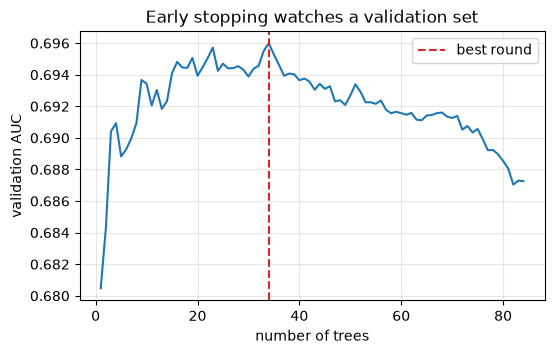

In [6]:
val_curve = es.evals_result()["validation_0"]["auc"]
for r in [10, 20, 30, es.best_iteration + 1, 50, 70, len(val_curve)]:
    print(f"after {r:>2} trees: validation AUC {val_curve[r - 1]:.3f}")
print(f"stopped after {len(val_curve)} trees = best round {es.best_iteration + 1} + 50 rounds of patience")

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(val_curve) + 1), val_curve)
plt.axvline(es.best_iteration + 1, color="tab:red", linestyle="--", label="best round")
plt.xlabel("number of trees"); plt.ylabel("validation AUC")
plt.title("Early stopping watches a validation set"); plt.legend(); plt.grid(alpha=.3); plt.show()

Instead of guessing `n_estimators`, set it high and let the validation set say stop. This is the single most useful habit with boosting libraries.

## 3. Missing values

Real customer tables have gaps. Hide 20% of `spend` values and try both models.

In [7]:
rng = np.random.default_rng(0)
X_gappy = X_train.copy()
X_gappy.loc[rng.random(len(X_gappy)) < 0.2, "spend"] = np.nan
print(f"missing spend values: {X_gappy['spend'].isna().sum()} of {len(X_gappy)}")

try:
    make_pipeline(StandardScaler(), LogisticRegression()).fit(X_gappy, y_train)
except ValueError as e:
    print("logistic regression:", str(e).split(".")[0])

missing spend values: 524 of 2487
logistic regression: Input X contains NaN


In [8]:
gappy = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42, n_jobs=4)
gappy.fit(X_gappy, y_train)
print(f"XGBoost trained with 20% missing spend: test AUC {roc_auc_score(y_test, gappy.predict_proba(X_test)[:, 1]):.3f}")

XGBoost trained with 20% missing spend: test AUC 0.737


At every split, XGBoost and LightGBM learn a **default direction** for missing values (left or right, whichever reduces the loss more). No imputation needed. You may still *want* to impute (04.3) when missingness should be explained to people, but you are not forced to.

## 4. Where boosting wins: thresholds and interactions

The fraud orders from lesson 00.1, now 20,000 of them. Fraud is defined by **cliffs**, not slopes: an account under 10 days old is risky, one 11 days old is not; an order over £300 is risky, one at £290 is not. And the rules combine with "and". A logistic regression can only say "risk rises steadily with total and falls steadily with account age", which is the wrong shape.

In [9]:
def make_orders(n, seed=0):
    """Orders like lesson 00.1: fraud = big order from a new account, OR very big order to a mismatched country."""
    rng = np.random.default_rng(seed)
    total = rng.gamma(2.0, 150, n)
    account_days = rng.integers(1, 1000, n)
    account_days = np.where(rng.random(n) < 0.25, rng.integers(1, 15, n), account_days)
    items = rng.integers(1, 15, n)
    country_match = rng.choice([0, 1], n, p=[0.15, 0.85])
    truth = ((total > 300) & (account_days < 10)) | ((country_match == 0) & (total > 500))
    fraud = (truth ^ (rng.random(n) < 0.03)).astype(int)        # 3% label noise
    return pd.DataFrame({"total": total, "account_days": account_days, "items": items,
                         "country_match": country_match, "fraud": fraud})

orders = make_orders(20_000)
fX, fy = orders.drop(columns="fraud"), orders["fraud"]
fX_train, fX_test, fy_train, fy_test = train_test_split(fX, fy, test_size=0.25, random_state=42, stratify=fy)
print(f"{len(orders):,} orders, fraud rate {fy.mean():.1%}")

20,000 orders, fraud rate 11.4%


In [10]:
rows = []
for name, model in make_models().items():
    t0 = time.time()
    model.fit(fX_train, fy_train)
    rows.append({"model": name, "test AUC": roc_auc_score(fy_test, model.predict_proba(fX_test)[:, 1]),
                 "fit time (s)": time.time() - t0})
pd.DataFrame(rows).set_index("model").round(3)

,test AUC,fit time (s)
model,,
logistic regression,0.815,0.005
random forest,0.885,0.628
XGBoost,0.873,0.110
LightGBM,0.874,0.165


Now every tree ensemble is far ahead of logistic regression (about 0.87–0.89 vs 0.82), and XGBoost and LightGBM fit 15,000 rows in well under a second. The random forest even edges the boosters here, which is another reason to always compare rather than assume. **The right model depends on the shape of the signal**, not on which library is fashionable. A good habit: always include logistic regression in your comparison. If boosting cannot beat it, your features are probably the bottleneck, not your model.

## 5. CatBoost, in one paragraph

CatBoost (Yandex) is the third big boosting library. Its speciality is **categorical features**: pass a column like `country` as text and it encodes it internally with a leak-resistant form of target encoding, so you skip one-hot encoding. It also tends to need less tuning. Install it with `pip install catboost` if you want to try it; the API is the same `fit` / `predict_proba`. It is not required for this course.

## Quiz answers

1. They are fast (histogram-based splits, parallelism), regularised (shrinkage, subsampling, L1/L2 penalties on leaves), handle missing values natively, and capture thresholds and interactions automatically, which is exactly what business tables are full of.
2. `learning_rate` and `n_estimators`: a smaller learning rate needs more trees. Use a small rate and let early stopping pick the number of trees.
3. A validation set taken from the training data. Never the test set: then the test score would no longer be an honest estimate.
4. Each split learns a default direction for missing values, chosen to reduce the loss most.
5. The churn signal in these five features is mostly monotone and nearly linear, and the dataset is small and noisy, so there is little for trees to add. The fraud target is defined by sharp thresholds (cliffs) combined with "and", a shape a single linear model cannot represent.

**Next:** [05.5 Support vector machines](../05-svm/) *(optional)*, or skip to [05.6 Hyperparameter tuning](../06-hyperparameter-tuning/).